<a href="https://colab.research.google.com/github/Shy-coder16/PROMPT-LOGIC/blob/main/CRIBA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


Saving RESUME2.docx to RESUME2.docx


### **Resume Summary:**

TECH (CSE), JIS UNIVERSITY (2022-2026)
Academic marks- 8.69 CGPA
CALCUTTA PUBLIC SCHOOL, BIDHAN PARK
Class 10 percentage- 93.8%
Class 12 percentage- 90.75%
Acquired 10th position in class, secured 160 state rank and achieved 3719 Olympiad rank in Smartkid General Knowledge Olympiad 2013
 Acquired 11th position in class, secured 55 state rank and achieved 1163 Olympiad rank in International Talent Hunt Olympiad 2013
Participated in One Day Seminar on Cyber Security Awareness Program 2022
Achieved 1st rank in Science Exposition(Chemistry) 2018
EXPERIENCE
STUDY SOLUTION TECHNICAL INSTITUTE, SINTHEE MORE             JULY 2022-PRESENT
Designated as Faculty, teaching various school courses to students and helping them regarding home works as well as in exam preparation
Centred at Java basics including inheritance and object-oriented programming   
SKILLS
SOFT SKILLS
Communication , Critical-thinking, Problem solving, Teamwork
HARD SKILLS
Microsoft Office, E-mail management, Programming skills , Database Management Looking for job opportunities as a fresher with basic knowledge in programming languages such as C, C++, JAVA, PYTHON, SCRATCH, Q-BASIC  and  Microsoft Office tools such as MS-WORD, MS-DOS, MS-EXCEL, MS-POWERPOINT, MS-ACCESS. ASHNA SINGH
A student of JIS University currently pursuing B.

### **Top Extracted skills:**

- Jis university

- B. tech

- Class

- Singh

- A student

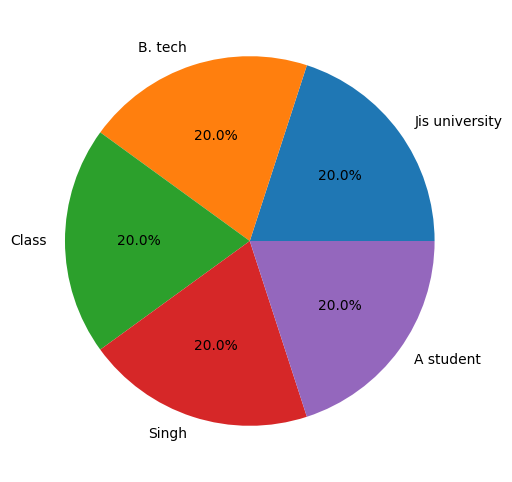

In [ ]:
!pip install nltk spacy python-docx pypdf --quiet
#resume summarizer extracting key skills
import os
import docx
import pypdf
import nltk
import spacy
from nltk.corpus import stopwords
from nltk.tokenize import sent_tokenize
from collections import Counter
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display, Markdown
nltk.download('punkt_tab')
#download resources
nltk.download('punkt')
nltk.download('stopwords')
spacy.cli.download("en_core_web_sm")
nlp=spacy.load("en_core_web_sm")
#resume
uploaded=files.upload()
file_name=next(iter(uploaded))
#extract text supporting docx and pdf
def extract_text(file_path):
  if file_path.endswith('.pdf') or 'PDF' in file_path or uploaded[file_path].startswith(b'%PDF'):
    # Read PDF
    reader = pypdf.PdfReader(file_path)
    text = ""
    for page in reader.pages:
      text += page.extract_text() or ""
    return text
  else:
    # Read DOCX
    doc=docx.Document(file_path)
    return "\n".join([para.text for para in doc.paragraphs])

resume_text=extract_text(file_name)

def summarize(text,num_sentences=3):
  words=nltk.word_tokenize(text.lower())
  stop_words=set(stopwords.words("english"))
  words=[word for word in words if word.isalnum() and word not in stop_words]
  word_freq=Counter(words)
  sentences=sent_tokenize(text)
  sentence_scores={}
  for sent in sentences:
    for word in nltk.word_tokenize(sent.lower()):
      if word in word_freq:
        sentence_scores[sent]=sentence_scores.get(sent,0)+word_freq[word]
  ranked_sentences=sorted(sentence_scores,key=sentence_scores.get,reverse=True)
  summary=" ".join(ranked_sentences[:num_sentences])
  return summary

summary=summarize(resume_text)
#skill extract
def extract_skills(text):
  doc=nlp(text.lower())
  skills=[]
  for chunk in doc.noun_chunks:
    if any(token.pos_ in ['NOUN','PROPN'] for token in chunk):
      skills.append(chunk.text.strip())
  common_skills=Counter(skills).most_common(5)
  return [skill for skill, _ in common_skills]
skills=extract_skills(resume_text)
#result
display(Markdown("### **Resume Summary:**"))
display(Markdown(summary))
display(Markdown("### **Top Extracted skills:**"))
for skill in skills:
  display(Markdown(f"- {skill.capitalize()}"))
#graph
plt.figure(figsize=(6,6))
labels=[skill.capitalize() for skill in skills]
sizes=[1]*len(skills)
plt.pie(sizes,labels=labels,autopct='%1.1f%%')
plt.show()

In [6]:
!pip install gradio nltk spacy python-docx pypdf --quiet

import os
import docx
import pypdf
import nltk
import spacy
from nltk.corpus import stopwords
from nltk.tokenize import sent_tokenize
from collections import Counter
import gradio as gr

# Download resources
nltk.download('punkt_tab', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)

try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    spacy.cli.download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm")

# Extract text supporting docx and pdf
def extract_text(file_path):
    if file_path.endswith('.pdf') or 'PDF' in file_path:
        reader = pypdf.PdfReader(file_path)
        text = ""
        for page in reader.pages:
            text += page.extract_text() or ""
        return text
    else:
        doc = docx.Document(file_path)
        return "\n".join([para.text for para in doc.paragraphs])

# Summarization
def summarize(text, num_sentences=3):
    words = nltk.word_tokenize(text.lower())
    stop_words = set(stopwords.words("english"))
    words = [word for word in words if word.isalnum() and word not in stop_words]
    word_freq = Counter(words)
    sentences = sent_tokenize(text)
    sentence_scores = {}
    for sent in sentences:
        for word in nltk.word_tokenize(sent.lower()):
            if word in word_freq:
                sentence_scores[sent] = sentence_scores.get(sent, 0) + word_freq[word]
    ranked_sentences = sorted(sentence_scores, key=sentence_scores.get, reverse=True)
    summary = " ".join(ranked_sentences[:num_sentences])
    return summary

# Skill extraction
def extract_skills(text):
    doc = nlp(text.lower())
    skills = []
    for chunk in doc.noun_chunks:
        if any(token.pos_ in ['NOUN', 'PROPN'] for token in chunk):
            skills.append(chunk.text.strip())
    common_skills = Counter(skills).most_common(5)
    return [skill for skill, _ in common_skills]

# Main Function updated for Gradio file handling
def process_resume(file):
    if file is None:
        return "No file uploaded.", "No skills found."
    text = extract_text(file.name)
    summary = summarize(text)
    skills = extract_skills(text)
    skills_formatted = "\n".join([f"- {s.capitalize()}" for s in skills])
    return summary, skills_formatted

# Advanced CSS for modern UI
custom_css = """
body {
    background: linear-gradient(to right, #fdfbe7, #e8f5e9);
    font-family: 'Segoe UI', sans-serif;
}
.gradio-container {
    padding: 20px;
    background-color: #ffffffd0;
    border-radius: 20px;
    box-shadow: 0 8px 24px rgba(0,0,0,0.1);
    margin: 30px auto;
    max-width: 900px;
}
.gr-button {
    background: linear-gradient(to right, #43cea2, #185a9d) !important;
    color: white !important;
    font-weight: bold !important;
    font-size: 16px !important;
    padding: 10px 20px !important;
    border-radius: 12px !important;
    border: none !important;
}
textarea, input, .gr-textbox {
    border-radius: 10px !important;
    font-size: 16px !important;
    padding: 10px !important;
}
h1, h2 {
    color: #2e7d32 !important;
    font-weight: 700 !important;
}
footer {
    display: none !important;
}
"""

# Gradio interface
with gr.Blocks(title="Resume Analyser") as demo:
    gr.Markdown("# Resume Summarizer & Skill Extractor")
    gr.Markdown("Upload your resume to instantly get a structured summary and highlight key skills.")

    with gr.Row():
        resume_file = gr.File(label="Upload Resume", file_types=[".docx", ".pdf"])
        submit_btn = gr.Button("Analyze")

    with gr.Row():
        summary_out = gr.Textbox(label="Resume Summary", lines=6, interactive=False)
        skills_out = gr.Textbox(label="Top Skills Extracted", lines=6, interactive=False)

    submit_btn.click(fn=process_resume, inputs=resume_file, outputs=[summary_out, skills_out])

# Setting debug=False prevents the cell from running indefinitely
demo.launch(debug=False, css=custom_css)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6c9482ed6c6d3c3d6c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
